# Question 5: SNAP enrollment and food shelf use

The ask: SNAP gives a household money to buy food. A food shelf gives a household food directly. Do the two move together, or does one replace the other? The SNAP benefits may change from time-to-time, what happens to food shelf activity when the SNAP benefits change? Does the relationship between SNAP benefits and food shelf activity differ across locations? Understanding the nature of this relationship helps The Food Group highlight the importance of SNAP to lawmakers and in turn helps them make better informed decisions.

**Required:** a public SNAP source joined to the food-shelf data, with **source, grain, and publication lag** stated (see Datasets below).

### How this notebook answers each part
| Sub-question | What we measure | Section |
|---|---|---|
| **Q5-A. Move together or substitute?** | Within-county co-movement of food-shelf activity with (i) SNAP **enrollment** and (ii) SNAP **benefit per person**, net of statewide month shocks | Q5-A |
| **Q5-B. What happens when benefits change?** | Natural experiment: end of SNAP **Emergency Allotments** (Apr 2023 in accounting months). Counties that lost more $/person = higher "dose". Plus the 2026 enrollment drop if food-shelf data reaches 2026 | Q5-B |
| **Q5-C. Does it differ across locations?** | Metro (7-county Twin Cities) vs Greater Minnesota; county-by-county response to the EA cut | Q5-C |

**Outcome metrics (reported separately, per the brief):** visits (`HouseholdsReg`), pounds distributed (`PoundsReg`), individuals served (`IndividualsReg`).

Datasets:
| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits (households), pounds distributed, individuals served |
| `Organization.xlsx` | Organization | Partner master file: type, status, location (`block_geoid` → county) |
| `Q5-snap-dashboard-data.xlsx` | County/Tribe × month (88 units, Jan 2016 – Aug 2026) | Monthly SNAP cases, persons, and net benefits issued (federal SNAP + state MFIP/MFAP food portions); joined to food-shelf data on county × month |
| `Q5-snap-dashboard-statewide-totals.xlsx` | Statewide × month (Jan 2016 – Aug 2026) | Statewide SNAP totals for trend charts and to check the county sums |

**SNAP source — grain & publication lag**
* **Grain:** county or Tribal Nation × month. Report month is the **accounting month** (when benefits were paid), net of cancelled payments.
* **Publication lag:** published monthly; data through **Aug 2026** was available when accessed on **2026-09-28** → about **1 month**.
* **Why this source:** monthly and county-level (joins directly to food-shelf county × month), back to 2016, covers the Emergency Allotment end. Chosen over the DHS calendar-year reports, which are annual summaries of the same counts.

Sources:
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — county/Tribe monthly data* (`snap-dashboard-data-through-august-2026.xlsx`), monthly by county or Tribal Nation (accounting month), Jan 2016 – Aug 2026; household cases, persons, and food benefits issued, cancelled, and net by funding source (federal SNAP, state MFAP, MFIP food portion). https://dcyf.mn.gov/snap-food-assistance-minnesota (data through August 2026; accessed 2026-09-28)
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — statewide totals* (`snap-dashboard-statewide-totals-through-august-2026.xlsx`), monthly, statewide, Jan 2016 – Aug 2026; same measures as above. https://dcyf.mn.gov/snap-food-assistance-minnesota (data through August 2026; accessed 2026-09-28)

## 1. Setup

### 1.1 Libraries and chart style

> **Purpose:** Load the packages used in every step and set one chart style (fixed color order, light grid) so all Q5 charts look consistent on the slides.

In [1]:
# !pip install -q statsmodels openpyxl   # uncomment if needed in Colab
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Chart palette (fixed order; validated categorical slots)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRID = "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

> **What this result means**
- No output. `statsmodels` runs the regressions; the four colors are always used in the same order (visits → pounds → SNAP persons → SNAP benefits).

### 1.2 Load the four files

> **Purpose:** Read the two Food Group files and the two DCYF SNAP files, and confirm their size and columns before any cleaning.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q5"

FS_PATH         = f"{DATA_DIR}/org_FSStats.xlsx"
ORG_PATH        = f"{DATA_DIR}/Organization.xlsx"
SNAP_PATH       = f"{DATA_DIR}/Q5-snap-dashboard-data.xlsx"
SNAP_STATE_PATH = f"{DATA_DIR}/Q5-snap-dashboard-statewide-totals.xlsx"

fs_raw   = pd.read_excel(FS_PATH)
org_raw  = pd.read_excel(ORG_PATH)
snap_raw = pd.read_excel(SNAP_PATH, parse_dates=["Report_Month"])
snap_st  = pd.read_excel(SNAP_STATE_PATH, parse_dates=["Report_Month"])

for name, df in [("org_FSStats", fs_raw), ("Organization", org_raw),
                 ("SNAP county", snap_raw), ("SNAP statewide", snap_st)]:
    print(f"{name:15s} {df.shape}")
    print("   ", list(df.columns)[:30], "\n")

Mounted at /content/drive
org_FSStats     (28287, 58)
    ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra'] 

Organization    (1202, 68)
    ['__ID', 'CreateTime', 'zzCreationTS', 'zzModificationTS', '_id_type', 'City', 'State', 'Zip', 'MailCity', 'MailState', 'MailZip', 'Eligibility', 'Conditions', 'MarketSeasons', 'zcountDaysOperations', 'Region', 'SuperRegion', 'County', 'StateDistrict', 'FederalDistrict', 'DistrictSection', 'AgencyType', '_id_subtype', 'AgencySubType', 'isFoodBank', 'isAgency', 'isDistributionSite', 'HoldsInventoryForOthers', 'isWebscmShipTo', 'WebscmShipToName'] 

SNAP county     (112

> **What this result means**
- `org_FSStats` has **28,287 site-month rows** and 58 columns. Most columns are deprecated; we only use the `Reg` metrics, `_id_site`, `_Year`, `_Month`.
- `Organization` has **1,202 partner records**. It supplies type, status and location (`block_geoid`).
- The SNAP county file has **11,208 rows** (88 county/Tribe units × Jan 2016 – Aug 2026). The statewide file has **128 months**.

### 1.3 Analysis settings

> **Purpose:** Keep every judgment call in one place (join key, food-shelf filter, error and outlier rules, balanced-panel threshold, Tribal handling, EA date) so it can be changed and re-run, and so each choice can be defended to judges.

In [3]:

# --- Food-shelf columns (confirmed in the Data Dictionary) ---
METRICS = {"HouseholdsReg": "visits", "PoundsReg": "pounds", "IndividualsReg": "individuals"}

# --- Join key (verified: org_FSStats._id_site matches Organization.__ID for 99.9% of rows) ---
FS_KEY     = "_id_site"   # site ID in org_FSStats (NOT __ID, which is the stats-row ID)
ORG_ID_COL = "__ID"       # organization ID in Organization

# --- Food-shelf filter ---
# Meal programs serve prepared meals, not grocery visits; farmers markets and the food bank are not food shelves.
# The same thing is labelled differently in the two tables, so all spellings are listed.
NON_SHELF_TYPES = ["Meal Program", "Meal Programs", "On-Site Meal Programs", "Farmers Market", "Food Bank"]
# A site is dropped if Organization types it as non-shelf OR most of its monthly records do
NON_SHELF_SITE_SHARE = 0.5

# --- Metric errors and outliers ---
HH_INDIV_ERROR_RATIO = 2.0            # HouseholdsReg / IndividualsReg >= this is impossible
ERROR_POLICY = "null_individuals"     # "null_individuals" | "null_both" | "keep"
SPIKE_MULTIPLE = 10                   # a site-month > 10x that site's own median is treated as a typo

# --- Panel construction ---
MIN_REPORT_SHARE = 0.9                # balanced panel: sites reporting in >= 90% of months
MIN_TRAILING_COVERAGE = 0.8           # drop trailing months where < 80% of usual sites have reported

# --- Geography ---
TRIBE_POLICY = "fold"                 # Tribal SNAP units: "fold" into the main county, or "drop"

# --- Policy date (accounting month). Last EA issuance was for Feb 2023 but PAID in March,
#     so the first month without EA in the dashboard is April 2023 (verified in §6.1). ---
EA_FIRST_POST = pd.Timestamp("2023-04-01")


> **What this result means**
- No output. The two v0.2 changes are a stricter **food-shelf filter** (meal programs under any label) and a new **spike rule** (`SPIKE_MULTIPLE`). Both were added because of what the v0.1 results showed (see §2.2 and §2.5).

### 1.4 Join-key check

> **Purpose:** Prove that `org_FSStats` and `Organization` are joined on the right column. A wrong key silently attaches the wrong county and type to every site.

In [4]:
def norm_key(s):
    # Compare IDs as clean strings so 123 and 123.0 match
    return s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)

fs_ids  = norm_key(fs_raw[FS_KEY])
org_ids = norm_key(org_raw[ORG_ID_COL])
print(f"{FS_KEY} → Organization.{ORG_ID_COL}: match rate {fs_ids.isin(set(org_ids.dropna())).mean():.1%}")
print(f"Organization.{ORG_ID_COL} unique: {org_ids.dropna().is_unique}")
# Diagnostic (2026-10-06): __ID↔__ID matched only by coincidence (stats-row ID), _id_bank / id_agency are
# the supplying food bank / parent agency, so _id_site is the correct site-level key.

_id_site → Organization.__ID: match rate 99.9%
Organization.__ID unique: True


> **What this result means**
- **99.9%** of food-shelf rows find their site in `Organization`, and the Organization ID is unique, so `_id_site → __ID` is a clean many-to-one join.
- The earlier auto-detected key (`__ID` on both sides) matched only by coincidence, because `org_FSStats.__ID` is a row number. `_id_bank` and `id_agency` point to the supplying food bank and the parent agency, not the site.

## 2. Clean the food-shelf data
Rules from the Data Dictionary and from checking the v0.1 output:
1. Use only the live **Reg** fields; Extra/Produce/Holiday/Total fields are deprecated.
2. Keep **food shelves** only.
3. Do **not** drop inactive sites from history; only drop months after their `InactiveDate`.
4. Fix impossible values: `HouseholdsReg > IndividualsReg`, negatives, one-sided zeros, and single-month spikes.
5. Recompute ratio columns instead of trusting the stored ones.

### 2.1 Attach organization attributes

> **Purpose:** Give every site-month its site's type, status and location from the master record, build a clean `month` column, and remove duplicate site-months.

In [5]:
fs  = fs_raw.copy()
org = org_raw.copy()
fs["_key"]  = norm_key(fs[FS_KEY])
org["_key"] = norm_key(org[ORG_ID_COL])

# Month from _Year/_Month (DateForSearch / zz*TS are system fields)
fs["month"] = pd.to_datetime(dict(year=pd.to_numeric(fs["_Year"], errors="coerce"),
                                  month=pd.to_numeric(fs["_Month"], errors="coerce"), day=1),
                             errors="coerce")
print(f"Unparseable months: {fs['month'].isna().sum():,}")
fs = fs.dropna(subset=["month"])

# Duplicate site-months: keep the most recently modified record
dup = fs.duplicated(["_key", "month"], keep=False)
print(f"Duplicate site-month rows: {dup.sum():,}")
if dup.any():
    fs = (fs.sort_values("zzModificationTS")
            .drop_duplicates(["_key", "month"], keep="last"))

org_keep = ["_key", "AgencyType", "AgencySubType", "isActive", "ActiveInactive",
            "InactiveDate", "block_geoid", "County"]
org = org[[c for c in org_keep if c in org.columns]].drop_duplicates("_key")

# AgencyType and County exist in both tables: keep both with suffixes
fs = fs.merge(org, on="_key", how="left", suffixes=("_fs", "_org"),
              validate="many_to_one", indicator=True)
print(f"Join match rate: {(fs['_merge'] == 'both').mean():.1%}")
fs = fs.drop(columns="_merge")
ORG_KEY = "_key"   # later cells group by this

# One county-name column for the geography fallback: master record first, stats record second
fs["County"] = fs["County_org"].fillna(fs["County_fs"])
county_name_cols = ["County"]

for col in ["AgencyType_fs", "AgencyType_org", "AgencySubType"]:
    if col in fs.columns:
        print(f"\n{col}:\n{fs[col].value_counts(dropna=False).to_string()}")

Unparseable months: 26
Duplicate site-month rows: 87
Join match rate: 99.9%

AgencyType_fs:
AgencyType_fs
Brick and Mortar Site      14692
Food Shelf                  7401
Outreach Program            2476
Meal Program                1593
On-Site Meal Programs       1039
Mobile                       354
Tribal Program               222
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9

AgencyType_org:
AgencyType_org
Brick and Mortar Site      21328
Outreach Program            3514
Meal Program                2699
Tribal Program               267
College Campus Program       265
NaN                          130
Agency or Tribal Nation       14

AgencySubType:
AgencySubType
NaN                    26046
Mobile                  2134
Pop-up Distribution       37


> **What this result means**
- **26 rows** have no valid year/month and are dropped. **87 duplicate site-months** are reduced to the most recently modified record.
- The join matches **99.9%** of rows.
- The two type columns disagree. `org_FSStats` calls 7,401 rows **"Food Shelf"** that Organization calls "Brick and Mortar Site", and it uses **three different labels for meal programs** (Meal Program, On-Site Meal Programs, Meal Programs). This is why §2.2 now checks both columns.
- `AgencySubType` is mostly blank (only Mobile and Pop-up are filled), so it cannot be the main filter.

### 2.2 Filter to food shelves

> **Purpose:** Keep only sites that hand groceries directly to households, which is what Q5 compares with SNAP. Meal programs, farmers markets and the food bank measure something else.

In [6]:
fs["is_non_shelf_fs"] = fs["AgencyType_fs"].isin(NON_SHELF_TYPES)
site_non_shelf_share = fs.groupby(ORG_KEY)["is_non_shelf_fs"].mean()
org_non_shelf = fs.groupby(ORG_KEY)["AgencyType_org"].first().isin(NON_SHELF_TYPES)
drop_sites = site_non_shelf_share.index[(site_non_shelf_share > NON_SHELF_SITE_SHARE) | org_non_shelf]

summary = (fs.assign(dropped=fs[ORG_KEY].isin(drop_sites))
             .groupby(["AgencyType_fs", "dropped"], dropna=False).size().unstack(fill_value=0))
print("Rows by org_FSStats type → kept / dropped")
print(summary.rename(columns={False: "kept", True: "dropped"}).sort_values("kept", ascending=False).to_string())

before_rows, before_sites = len(fs), fs[ORG_KEY].nunique()
fs = fs[~fs[ORG_KEY].isin(drop_sites)].copy()
assert len(fs) > 0, "Filter removed every row: check NON_SHELF_TYPES"
print(f"\nDropped {before_sites - fs[ORG_KEY].nunique():,} sites / {before_rows - len(fs):,} rows")
print(f"Food-shelf rows kept: {len(fs):,} | sites: {fs[ORG_KEY].nunique():,} | "
      f"months: {fs['month'].min():%Y-%m} → {fs['month'].max():%Y-%m}")

Rows by org_FSStats type → kept / dropped
dropped                   kept  dropped
AgencyType_fs                          
Brick and Mortar Site    14692        0
Food Shelf                7401        0
Outreach Program          2476        0
Mobile                     354        0
Tribal Program             222        0
College Campus Program     165        0
NaN                        138        0
Meal Program                22     1571
Other Non-Profit            22        0
Agency or Tribal Nation     17        0
Brick and Mortar Sites       9        0
On-Site Meal Programs        0     1039
Meal Programs                0       89

Dropped 65 sites / 2,699 rows
Food-shelf rows kept: 25,518 | sites: 600 | months: 2022-01 → 2026-07


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **v0.1 result:** filtering on Organization's type only removed "Meal Program" and kept **25,518 rows from 600 sites**. Meal sites that `org_FSStats` labels "On-Site Meal Programs" or "Meal Programs" (about 1,100 rows) slipped through.
- **v0.2 rule:** a site is dropped if Organization types it as non-shelf **or** most of its own monthly records do. Filtering by site, not by row, avoids cutting random months out of a site's history.
- Expect fewer sites than 600 after re-running. **Record the new count here and on the methods slide.**

### 2.3 Drop months after a site closed

> **Purpose:** Remove records dated after a site's `InactiveDate` (late or test entries) without deleting the site's real history. Dropping every inactive site would erase food shelves that closed in 2024 from the 2022–23 data and bias the trend.

In [7]:
if "InactiveDate" in fs.columns:
    inact = pd.to_datetime(fs["InactiveDate"], errors="coerce")
    after_close = inact.notna() & (fs["month"] > inact)
    print(f"Rows after InactiveDate dropped: {after_close.sum():,}")
    fs = fs[~after_close].copy()

Rows after InactiveDate dropped: 30


> **What this result means**
- Only **30 rows** fall after a closing date, so status filtering barely affects the data. History from sites that later closed is kept.

### 2.4 Not-reported months and Households > Individuals errors

> **Purpose:** Separate "site did not report" from "site served zero people", and fix the rows that break the rule Individuals ≥ Households (a household has at least one person).

In [8]:
for c in METRICS:
    fs[c] = pd.to_numeric(fs[c], errors="coerce")

not_reported = (fs["HouseholdsReg"].fillna(0) == 0) & (fs["PoundsReg"].fillna(0) == 0)
fs.loc[not_reported, list(METRICS)] = np.nan

ratio = fs["HouseholdsReg"] / fs["IndividualsReg"].replace(0, np.nan)
fs["flag_hh_gt_indiv"] = ratio >= HH_INDIV_ERROR_RATIO
print(f"Not-reported site-months: {not_reported.sum():,}")
print(f"Flagged HH>Indiv errors (ratio >= {HH_INDIV_ERROR_RATIO}): {fs['flag_hh_gt_indiv'].sum():,}")

if ERROR_POLICY == "null_individuals":
    fs.loc[fs["flag_hh_gt_indiv"], "IndividualsReg"] = np.nan
elif ERROR_POLICY == "null_both":
    fs.loc[fs["flag_hh_gt_indiv"], ["IndividualsReg", "HouseholdsReg"]] = np.nan

# Recompute ratios from cleaned values (do not use stored PoundsPerHH etc.)
fs["pounds_per_hh"] = fs["PoundsReg"] / fs["HouseholdsReg"]
fs["indiv_per_hh"]  = fs["IndividualsReg"] / fs["HouseholdsReg"]
fs[list(METRICS) + ["pounds_per_hh", "indiv_per_hh"]].describe().T

Not-reported site-months: 1,016
Flagged HH>Indiv errors (ratio >= 2.0): 22


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


,count,mean,std,min,25%,50%,75%,max
HouseholdsReg,24405.0,5.135334e+02,2180.126903,0.0,63.000000,153.000000,458.000000,273385.0
PoundsReg,24398.0,2.697342e+04,54484.192229,-4415.0,3280.000000,8261.000000,26105.750000,994394.0
IndividualsReg,24390.0,1.513769e+03,4075.857038,0.0,157.000000,422.000000,1279.000000,89669.0
pounds_per_hh,24331.0,NaN,NaN,-inf,38.562562,56.909091,79.064892,inf
indiv_per_hh,24374.0,inf,NaN,0.0,2.222222,2.733333,3.323302,inf


> **What this result means**
- **1,016 site-months** have zero visits and zero pounds. These are treated as *not reported*, not as zero demand.
- **22 rows** have Households at least 2× Individuals. Their Individuals value is set to missing (Individuals is self-reported); Households and Pounds are kept.
- The summary table shows problems this step does not fix. **Households max = 273,385** for one site-month (median 153), **Pounds has negative values** (min −4,415), and the ratio columns hit **±inf** because some months have 0 households but positive pounds. These distort every statewide total and regression downstream, so §2.5 was added.

### 2.5 Invalid values and single-month spikes (new in v0.2)

> **Purpose:** Remove values that cannot be real before aggregating: negatives, one-sided zeros, and single-month typos such as an extra digit. Each site is compared with its own median, so a small rural shelf and a large metro shelf are judged on their own scale.

In [9]:
M = list(METRICS)

# 1) Negative counts or pounds are impossible
neg = fs[M] < 0
fs[M] = fs[M].mask(neg)

# 2) One-sided zeros: 0 households but food went out (or the reverse) = incomplete entry
hh0 = (fs["HouseholdsReg"] == 0) & (fs["PoundsReg"] > 0)
lb0 = (fs["PoundsReg"] == 0) & (fs["HouseholdsReg"] > 0)
fs.loc[hh0, ["HouseholdsReg", "IndividualsReg"]] = np.nan
fs.loc[lb0, "PoundsReg"] = np.nan

# 3) Single-month spikes: > SPIKE_MULTIPLE x the site's own median
site_med = fs.groupby(ORG_KEY)[M].transform("median")
spike = (fs[M] > SPIKE_MULTIPLE * site_med) & (site_med > 0)
top = (fs.loc[spike["HouseholdsReg"], [ORG_KEY, "month", "HouseholdsReg"]]
         .assign(site_median=site_med.loc[spike["HouseholdsReg"], "HouseholdsReg"])
         .sort_values("HouseholdsReg", ascending=False).head(10))
fs[M] = fs[M].mask(spike)

print(f"Negative values removed: {neg.sum().to_dict()}")
print(f"0 households but pounds > 0: {hh0.sum():,} | 0 pounds but households > 0: {lb0.sum():,}")
print(f"Spikes > {SPIKE_MULTIPLE}x site median: {spike.sum().to_dict()}")
print("\nLargest household spikes removed:"); print(top.to_string(index=False))

# 4) Carry-forward check: identical numbers to the previous month (possible copy-paste reporting)
fs = fs.sort_values([ORG_KEY, "month"])
same_as_prev = (fs.groupby(ORG_KEY)[M].shift(1) == fs[M]).all(axis=1) & fs[M].notna().all(axis=1)
fs["flag_carry_forward"] = same_as_prev
print(f"\nSite-months identical to the previous month on all 3 metrics: {same_as_prev.sum():,} "
      f"({same_as_prev.mean():.1%}) — flagged, not removed")

# Recompute ratios from the cleaned values
fs["pounds_per_hh"] = fs["PoundsReg"] / fs["HouseholdsReg"]
fs["indiv_per_hh"]  = fs["IndividualsReg"] / fs["HouseholdsReg"]
fs[M + ["pounds_per_hh", "indiv_per_hh"]].describe().T.round(1)

Negative values removed: {'HouseholdsReg': 0, 'PoundsReg': 4, 'IndividualsReg': 0}
0 households but pounds > 0: 7 | 0 pounds but households > 0: 13
Spikes > 10x site median: {'HouseholdsReg': 35, 'PoundsReg': 19, 'IndividualsReg': 17}

Largest household spikes removed:
 _key      month  HouseholdsReg  site_median
 1197 2023-07-01       273385.0        434.0
 1304 2025-03-01        83909.0       2708.0
 1417 2025-11-01         6670.0         78.0
 1083 2024-11-01         4203.0        400.0
15306 2024-04-01         3257.0         64.5
 1245 2023-06-01         2247.0        220.0
14674 2025-04-01         1688.0         96.0
 1277 2025-07-01         1590.0         22.0
15309 2026-02-01         1519.0         86.0
15309 2026-04-01         1367.0         86.0

Site-months identical to the previous month on all 3 metrics: 218 (0.9%) — flagged, not removed


,count,mean,std,min,25%,50%,75%,max
HouseholdsReg,24363.0,498.1,1190.0,0.0,63.0,152.0,456.0,21382.0
PoundsReg,24362.0,26966.6,54481.2,12.0,3284.2,8261.0,26093.5,994394.0
IndividualsReg,24366.0,1511.7,4074.2,0.0,157.0,421.0,1277.0,89669.0
pounds_per_hh,24259.0,62.9,44.9,0.3,38.6,57.0,79.0,2164.0
indiv_per_hh,24329.0,2.9,1.4,0.0,2.2,2.7,3.3,100.0


> **What this result means**
- Not run yet. After re-running, check three things:
- The **Households max** should drop from 273,385 to a believable single-site value, and **min Pounds** should be ≥ 0.
- `pounds_per_hh` and `indiv_per_hh` should have **no inf** values.
- The **carry-forward** share: in v0.1, Aitkin reported exactly the same numbers in Jan and Feb 2022 (177 visits / 8,831 lb / 400 people). If this share is more than a few percent, mention it as a reporting-quality caveat.

## 3. Geography: map each site to a SNAP unit

### 3.1 County → SNAP-unit crosswalk

> **Purpose:** Put both datasets on the same geography. The SNAP dashboard is not a clean 87-county list.

`block_geoid` → first 5 digits = county FIPS → county name.

The SNAP dashboard is not a clean 87-county list, so we build a **`snap_unit`** that both sides share:

| SNAP dashboard entity | What it covers | Food-shelf counties mapped to it |
|---|---|---|
| `MNPrairie` | Dodge + Steele + Waseca consortium | Dodge, Steele, Waseca |
| `Pope` (from Jan 2022) | Western Prairie Human Services = Pope + Grant (Grant series ends Dec 2021) | Pope, Grant |
| `Mille Lacs Band`, `Red Lake Nation`, `White Earth Band` | Tribal Nations administer their own SNAP | `TRIBE_POLICY="fold"` adds them to Mille Lacs, Beltrami, Mahnomen |

All other units are single counties.

In [10]:
# Minnesota counties in DHS county-code order (code n -> FIPS 27 + (2n-1)), spelled as in the SNAP dashboard
MN_COUNTIES = ["Aitkin","Anoka","Becker","Beltrami","Benton","Big Stone","Blue Earth","Brown","Carlton","Carver",
    "Cass","Chippewa","Chisago","Clay","Clearwater","Cook","Cottonwood","Crow Wing","Dakota","Dodge","Douglas",
    "Faribault","Fillmore","Freeborn","Goodhue","Grant","Hennepin","Houston","Hubbard","Isanti","Itasca","Jackson",
    "Kanabec","Kandiyohi","Kittson","Koochiching","Lac Qui Parle","Lake","Lake of Woods","Le Sueur","Lincoln","Lyon",
    "McLeod","Mahnomen","Marshall","Martin","Meeker","Mille Lacs","Morrison","Mower","Murray","Nicollet","Nobles",
    "Norman","Olmsted","Otter Tail","Pennington","Pine","Pipestone","Polk","Pope","Ramsey","Red Lake","Redwood",
    "Renville","Rice","Rock","Roseau","St. Louis","Scott","Sherburne","Sibley","Stearns","Steele","Stevens","Swift",
    "Todd","Traverse","Wabasha","Wadena","Waseca","Washington","Watonwan","Wilkin","Winona","Wright","Yellow Medicine"]
assert len(MN_COUNTIES) == 87
FIPS_TO_COUNTY = {f"27{2*i+1:03d}": name for i, name in enumerate(MN_COUNTIES)}

COUNTY_TO_UNIT = {c: c for c in MN_COUNTIES}
COUNTY_TO_UNIT.update({"Dodge": "MNPrairie", "Steele": "MNPrairie", "Waseca": "MNPrairie", "Grant": "Pope"})
TRIBE_TO_COUNTY = {"Mille Lacs Band": "Mille Lacs", "Red Lake Nation": "Beltrami", "White Earth Band": "Mahnomen"}

METRO7 = {"Anoka", "Carver", "Dakota", "Hennepin", "Ramsey", "Scott", "Washington"}

def norm_county(s):
    # Normalize free-text county names to the dashboard spelling
    s = str(s).strip().replace(" County", "").title()
    fixes = {"Lac Qui Parle": "Lac Qui Parle", "Lake Of The Woods": "Lake of Woods", "Lake Of Woods": "Lake of Woods",
             "Saint Louis": "St. Louis", "St Louis": "St. Louis", "St. Louis": "St. Louis", "Mcleod": "McLeod"}
    return fixes.get(s, s)

geoid = fs["block_geoid"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(15) \
        if "block_geoid" in fs.columns else pd.Series(pd.NA, index=fs.index, dtype="string")
fs["county"] = geoid.str[:5].map(FIPS_TO_COUNTY)
if county_name_cols:   # fallback when block_geoid is blank
    fs["county"] = fs["county"].fillna(fs[county_name_cols[0]].map(norm_county))
fs["county"] = fs["county"].where(fs["county"].isin(MN_COUNTIES))
fs["snap_unit"] = fs["county"].map(COUNTY_TO_UNIT)

unmatched = fs.loc[fs["snap_unit"].isna(), ORG_KEY].nunique()
print(f"Sites without a Minnesota county: {unmatched} (excluded from the join)")
fs = fs[fs["snap_unit"].notna()].copy()
print(f"Sites kept: {fs[ORG_KEY].nunique():,} across {fs['snap_unit'].nunique()} SNAP units")

Sites without a Minnesota county: 45 (excluded from the join)
Sites kept: 555 across 83 SNAP units


> **What this result means**
- **45 sites** have no Minnesota county (blank `block_geoid` and no usable county name) and are excluded from the join.
- **555 sites** map to **83 of the 84 SNAP units**. Merging Dodge/Steele/Waseca and Grant/Pope turns 87 counties into 84 units, so almost every unit has at least one reporting food shelf.

## 4. SNAP data and the county × month panel

### 4.1 SNAP variables

> **Purpose:** Turn the DCYF file into the two SNAP measures Q5 needs: how many people are enrolled, and how much food money each person gets. Then check the county file against the statewide file.

* `snap_persons` = `PersonCount` → **enrollment**
* `snap_benefits` = `Total_Net` (federal SNAP + state MFAP + MFIP food portion, net of cancellations). We use the total because `PersonCount` covers all three.
* `benefit_pp` = `snap_benefits / snap_persons` → **benefit generosity**. This is what dropped when Emergency Allotments ended.

In [11]:
snap = snap_raw.rename(columns={"Report_Month": "month", "CountyTribeName": "entity"}).copy()
snap["month"] = snap["month"].dt.to_period("M").dt.to_timestamp()

if TRIBE_POLICY == "fold":
    snap["snap_unit"] = snap["entity"].replace(TRIBE_TO_COUNTY)
else:
    snap = snap[~snap["entity"].isin(TRIBE_TO_COUNTY)]
    snap["snap_unit"] = snap["entity"]

snap = (snap.groupby(["snap_unit", "month"], as_index=False)
            .agg(snap_cases=("CaseCount", "sum"), snap_persons=("PersonCount", "sum"),
                 snap_benefits=("Total_Net", "sum"), snap_fed_net=("SNAP_Federal_Food_Net", "sum")))
snap["benefit_pp"] = snap["snap_benefits"] / snap["snap_persons"]

# Check: county sums vs statewide file
chk = snap.groupby("month")[["snap_persons", "snap_benefits"]].sum().join(
      snap_st.set_index(snap_st["Report_Month"].dt.to_period("M").dt.to_timestamp())[["PersonCount", "Total_Net"]])
gap_persons  = float((chk["snap_persons"] / chk["PersonCount"] - 1).abs().max() * 100)
gap_benefits = float((chk["snap_benefits"] / chk["Total_Net"] - 1).abs().max() * 100)
print(f"Max abs % gap county-sum vs statewide: persons {round(gap_persons, 2)}%, benefits {round(gap_benefits, 2)}%")

Max abs % gap county-sum vs statewide: persons 0.0%, benefits 0.0%


> **What this result means**
- The county units add up to the statewide file **exactly (0.0% gap)** for both persons and benefits, so folding the Tribal units and consortia did not lose or double-count anyone.
- Code note: `round()` failed in v0.1 because the value was a NumPy scalar. It is now converted with `float()` and rounded with Python's `round()`.

### 4.2 Aggregate food shelves to SNAP unit × month

> **Purpose:** Add up site-level visits, pounds and individuals to the SNAP geography. Build a **balanced panel** of steadily reporting sites so that rising totals reflect demand, not new sites joining the system.

In [12]:
# Late reporting: the most recent months may not have all sites in yet. Trim them so they don't look like a drop.
sites_per_month = fs.dropna(subset=["HouseholdsReg"]).groupby("month")[ORG_KEY].nunique()
typical = sites_per_month.iloc[:-6].median()
tail_ok = (sites_per_month / typical >= MIN_TRAILING_COVERAGE)
last_good = tail_ok[tail_ok].index.max()
dropped_tail = sites_per_month[sites_per_month.index > last_good]
print(f"Typical reporting sites/month: {typical:.0f}. Trailing months dropped: {list(dropped_tail.index.strftime('%Y-%m'))}")
fs = fs[fs["month"] <= last_good].copy()

months_all = fs["month"].nunique()
share = fs.dropna(subset=["HouseholdsReg"]).groupby(ORG_KEY)["month"].nunique() / months_all
balanced_sites = share[share >= MIN_REPORT_SHARE].index
print(f"Balanced-panel sites: {len(balanced_sites):,} of {fs[ORG_KEY].nunique():,}")

def agg_fs(df):
    return (df.groupby(["snap_unit", "month"], as_index=False)
              .agg(visits=("HouseholdsReg", "sum"), pounds=("PoundsReg", "sum"),
                   individuals=("IndividualsReg", "sum"), n_sites=(ORG_KEY, "nunique")))

fs_all = agg_fs(fs.dropna(subset=["HouseholdsReg"]))
fs_bal = agg_fs(fs[fs[ORG_KEY].isin(balanced_sites)].dropna(subset=["HouseholdsReg"]))

Typical reporting sites/month: 442. Trailing months dropped: []
Balanced-panel sites: 361 of 555


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **No trailing months were dropped.** About 443 sites report in a typical month and the latest months are already complete, so late reporting is not an issue in this extract.
- **361 of 555 sites (65%)** report in at least 90% of months. These form the balanced panel used for inference. The other 194 enter, exit, or report irregularly, and they appear only in the `all sites` robustness version.

### 4.3 Join food shelves with SNAP

> **Purpose:** Create the analysis table: one row per SNAP unit per month with food-shelf activity, SNAP enrollment, SNAP benefit per person, logs, and year-over-year (YoY) changes.

In [13]:
def build_panel(fs_agg):
    p = fs_agg.merge(snap, on=["snap_unit", "month"], how="inner", validate="one_to_one")
    p["metro"] = p["snap_unit"].isin(METRO7).astype(int)
    p["moy"] = p["month"].dt.month                      # month-of-year (seasonality)
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        p[f"ln_{c}"] = np.log(p[c].where(p[c] > 0))
    # Year-over-year log change (removes seasonality without needing pre-2022 food-shelf data)
    p = p.sort_values(["snap_unit", "month"])
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        lag12 = p.groupby("snap_unit")[f"ln_{c}"].shift(12)
        same_gap = p.groupby("snap_unit")["month"].shift(12) == p["month"] - pd.DateOffset(months=12)
        p[f"yoy_{c}"] = (p[f"ln_{c}"] - lag12).where(same_gap)
    return p

panel_all = build_panel(fs_all)
panel     = build_panel(fs_bal)      # default
print(f"Panel: {panel['snap_unit'].nunique()} units × {panel['month'].nunique()} months = {len(panel):,} rows")
print(f"Coverage: {panel['month'].min():%Y-%m} → {panel['month'].max():%Y-%m}")
panel.head()

Panel: 83 units × 55 months = 4,559 rows
Coverage: 2022-01 → 2026-07


,snap_unit,month,visits,pounds,individuals,n_sites,snap_cases,snap_persons,snap_benefits,snap_fed_net,benefit_pp,metro,moy,ln_visits,ln_pounds,ln_individuals,ln_snap_persons,ln_benefit_pp,yoy_visits,yoy_pounds,yoy_individuals,yoy_snap_persons,yoy_benefit_pp
0,Aitkin,2022-01-01,177.0,8831.0,400.0,4,685,1231,275717,259867,223.978067,0,1,5.176150,9.086024,5.991465,7.115582,5.411548,NaN,NaN,NaN,NaN,NaN
1,Aitkin,2022-02-01,177.0,8831.0,400.0,4,686,1230,286856,268919,233.216260,0,2,5.176150,9.086024,5.991465,7.114769,5.451966,NaN,NaN,NaN,NaN,NaN
2,Aitkin,2022-03-01,193.0,9803.0,423.0,4,688,1222,281177,265086,230.095745,0,3,5.262690,9.190444,6.047372,7.108244,5.438496,NaN,NaN,NaN,NaN,NaN
3,Aitkin,2022-04-01,240.0,10879.0,418.0,4,690,1213,279020,261859,230.024732,0,4,5.480639,9.294590,6.035481,7.100852,5.438187,NaN,NaN,NaN,NaN,NaN
4,Aitkin,2022-05-01,197.0,11423.0,460.0,4,700,1215,282679,264152,232.657613,0,5,5.283204,9.343384,6.131226,7.102499,5.449568,NaN,NaN,NaN,NaN,NaN


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- The panel has **83 units × 55 months (Jan 2022 – Jul 2026) = 4,559 rows**. The food-shelf data ends in July 2026, inside the SNAP coverage (Aug 2026), so no food-shelf months are lost in the join.
- YoY changes start in Jan 2023 because food-shelf data begins in Jan 2022. Comparing each month with the same month a year earlier removes seasonality without needing older data.
- The first rows show the carry-forward pattern flagged in §2.5: Aitkin has identical values in Jan and Feb 2022.

## 5. Q5-A — Do SNAP and food shelves move together, or does one replace the other?

### 5.1 Statewide picture (index, Jan 2022 = 100)

> **Purpose:** Show the big picture in one chart before any modelling: how food-shelf activity and SNAP moved over the same months, especially around the end of Emergency Allotments (EA).

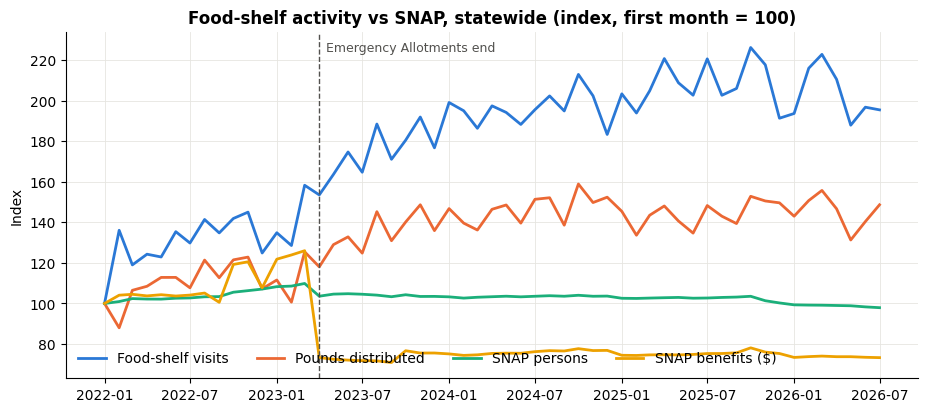

In [14]:
state = (panel.groupby("month")[["visits", "pounds", "individuals"]].sum()
         .join(snap.groupby("month")[["snap_persons", "snap_benefits"]].sum()))
base = state.iloc[0]
idx = state / base * 100

fig, ax = plt.subplots()
for col, color, label in [("visits", C1, "Food-shelf visits"), ("pounds", C2, "Pounds distributed"),
                          ("snap_persons", C3, "SNAP persons"), ("snap_benefits", C4, "SNAP benefits ($)")]:
    ax.plot(idx.index, idx[col], color=color, label=label)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.annotate("Emergency Allotments end", (EA_FIRST_POST, ax.get_ylim()[1]), xytext=(5, -14),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("Food-shelf activity vs SNAP, statewide (index, first month = 100)")
ax.set_ylabel("Index"); ax.legend(frameon=False, ncol=4, loc="lower left")
plt.show()

> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **SNAP benefits** (yellow) fall about 40% at the EA end (index ≈125 → ≈75) and stay flat afterwards. **SNAP persons** (green) barely move and dip slightly in 2026.
- **Food-shelf visits** (blue) roughly **double** between 2022 and 2024 and stay high. **Pounds** (orange) rise less (about +45–50%), so each visit now takes home less food.
- The visits spike to **index ≈415 in July 2023** (and ≈280 in Feb 2025) is the data error removed in §2.5, not real demand.
- **Statewide, the two move in opposite directions.** SNAP money per person dropped and food-shelf use rose. This fits **substitution**, but it is one event that coincides with high 2023 food prices (Q4), so the chart alone cannot separate the two causes.

### 5.2 Lead/lag correlation of YoY changes (statewide)

> **Purpose:** Test whether changes in SNAP come *before* changes in food-shelf use, and by how many months. A negative correlation with benefit per person means less SNAP money is followed by more food-shelf use.

In [15]:
st = state.copy()
st["benefit_pp"] = st["snap_benefits"] / st["snap_persons"]
yoy = np.log(st).diff(12)
rows = []
for k in range(0, 7):
    rows.append({"lag_months": k,
                 "corr(visits, benefit_pp)":   yoy["visits"].corr(yoy["benefit_pp"].shift(k)),
                 "corr(visits, snap_persons)": yoy["visits"].corr(yoy["snap_persons"].shift(k)),
                 "corr(pounds, benefit_pp)":   yoy["pounds"].corr(yoy["benefit_pp"].shift(k))})
pd.DataFrame(rows).round(2)

,lag_months,"corr(visits, benefit_pp)","corr(visits, snap_persons)","corr(pounds, benefit_pp)"
0,0,-0.66,0.16,-0.56
1,1,-0.71,0.11,-0.63
2,2,-0.63,0.31,-0.64
3,3,-0.61,0.36,-0.62
4,4,-0.57,0.42,-0.62
5,5,-0.52,0.49,-0.56
6,6,-0.52,0.50,-0.57


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **Visits vs SNAP benefit per person:** about **−0.5 at lags 0–3 months**, then near **0 from 4 months**. When SNAP money per person falls, visits rise within about a quarter.
- **Pounds vs benefit per person:** about **−0.56 to −0.64** at every lag. The pounds response is larger and lasts longer.
- **Visits vs SNAP persons:** **positive** (0.19 → 0.64). Enrollment and food-shelf use rise together, which suggests both track the same underlying need.
- Caveat: this is one statewide series of about 40 YoY months dominated by the EA drop, so it is descriptive evidence, not proof.

### 5.3 Panel regression with county and month fixed effects

> **Purpose:** Ask the same question *within* each county. Is a county busier at its food shelves in months when its own SNAP enrollment or benefit per person is higher, after removing statewide shocks?

$$\ln Y_{ct} = \beta_1 \ln(\text{SNAP persons})_{ct} + \beta_2 \ln(\text{benefit per person})_{ct} + \alpha_c + \gamma_t + \varepsilon_{ct}$$

* $\alpha_c$ (unit fixed effects): compares each county **with itself**, so no population data is needed.
* $\gamma_t$ (month fixed effects): absorbs statewide shocks such as inflation, seasonality, and the statewide EA cut.
* Standard errors are clustered by SNAP unit.

**Interpretation:** $\beta_1 > 0$ means enrollment and food-shelf use **move together** (both track need). $\beta_2 < 0$ means more generous SNAP **replaces** food-shelf use. Both can hold at once.

In [16]:
def fe_reg(df, y, rhs="ln_snap_persons + ln_benefit_pp", extra=""):
    d = df.dropna(subset=[y, "ln_snap_persons", "ln_benefit_pp"])
    m = smf.ols(f"{y} ~ {rhs} {extra} + C(snap_unit) + C(month)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["snap_unit"])[0]})
    return m

res = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    m = fe_reg(panel, y)
    for v in ["ln_snap_persons", "ln_benefit_pp"]:
        res.append({"outcome": y, "term": v, "coef": m.params[v], "se": m.bse[v],
                    "p": m.pvalues[v], "n": int(m.nobs)})
q5a = pd.DataFrame(res).round(3)
q5a

,outcome,term,coef,se,p,n
0,ln_visits,ln_snap_persons,0.160,0.106,0.133,4559
1,ln_visits,ln_benefit_pp,0.400,0.193,0.038,4559
2,ln_pounds,ln_snap_persons,-0.041,0.140,0.771,4558
3,ln_pounds,ln_benefit_pp,0.308,0.206,0.136,4558
4,ln_individuals,ln_snap_persons,0.126,0.113,0.267,4558
5,ln_individuals,ln_benefit_pp,0.253,0.193,0.190,4558


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **Enrollment (β₁):** +0.17 for visits (p = 0.10), small and not significant for pounds and individuals. There is weak evidence that counties with rising enrollment also see rising visits.
- **Benefit per person (β₂):** **+0.39 for visits (p = 0.04)**. This is the *opposite* sign from substitution, but it is not robust: in the `all sites` version (§8) it becomes −0.03 (p = 0.90).
- **Why the within-county result is weak:** month fixed effects absorb the statewide EA cut, which is the main source of benefit change. What remains is small county differences in benefit per person, which mostly reflect household mix (e.g. more children or seniors), not policy.
- **Takeaway for Q5-A:** the clear pattern is the **statewide** one in §5.1–5.2. The within-county model adds no reliable extra signal, so present it as a robustness check, not the headline.

## 6. Q5-B — What happens to food shelves when SNAP benefits change?

### 6.1 The benefit change: end of Emergency Allotments

> **Purpose:** Confirm when the EA cut appears in the SNAP data and how large it was in each county (the "dose").

Every SNAP household got EA through the Feb 2023 issuance; then it stopped. Because the dashboard uses **accounting months**, the Feb 2023 EA payment shows up in **March**, so the drop appears in **April 2023** (printed below). The cut was statewide, but the **size of the cut per person differed by county**. That difference is our "dose":

$$\text{dose}_c = \overline{\text{benefit\_pp}}_{c,\,\text{Jan–Mar 2023}} - \overline{\text{benefit\_pp}}_{c,\,\text{Apr–Jun 2023}}$$

**Design (dose-response difference-in-differences on YoY changes):**
* **Pre:** Jan–Mar 2023 vs Jan–Mar 2022. Both years had EA, so this works as a placebo.
* **Post:** Apr–Sep 2023 vs Apr–Sep 2022. EA was present in 2022 and absent in 2023.
* Outcome = post YoY change − pre YoY change, regressed on dose (in $10 per person).

If the coefficient is **positive**, counties that lost more SNAP money saw food-shelf use rise more, which is evidence of **substitution**.

In [17]:
ppm = snap.set_index(["snap_unit", "month"])["benefit_pp"].unstack()
print("Statewide benefit per person around the EA end:")
print((snap.groupby("month")[["snap_benefits", "snap_persons"]].sum()
       .assign(benefit_pp=lambda d: d.snap_benefits / d.snap_persons)
       .loc["2022-11":"2023-06", "benefit_pp"].round(1)).to_string())

dose = (ppm.loc[:, "2023-01":"2023-03"].mean(axis=1) - ppm.loc[:, "2023-04":"2023-06"].mean(axis=1)).rename("dose")
print("\nEA cut per SNAP person ($/month) across units:")
print(dose.describe().round(1).to_string())
# Note: if the spread is small, the cross-county test has limited power. Say so on the slide.

Statewide benefit per person around the EA end:
month
2022-11-01    256.9
2022-12-01    227.9
2023-01-01    254.9
2023-02-01    258.6
2023-03-01    259.9
2023-04-01    160.3
2023-05-01    157.0
2023-06-01    155.8

EA cut per SNAP person ($/month) across units:
count     84.0
mean     110.5
std        9.3
min       84.6
25%      105.3
50%      112.9
75%      116.9
max      126.1


> **What this result means**
- Statewide benefit per person was **$260 in March 2023 and $160 in April 2023 (−38%)**. This confirms April 2023 as the first month without EA in accounting months. The December 2022 dip ($228) is a payment-timing artefact.
- The cut averaged **$110 per SNAP person per month**. Across units it ranges only from **$85 to $126 (sd $9)**, so almost every county lost about the same amount per person. With so little variation, the cross-county comparison in §6.2 has little power.

### 6.2 Dose-response difference-in-differences

> **Purpose:** Test whether counties that lost more SNAP money per person saw a bigger rise in food-shelf use after April 2023, using the change in YoY growth from before to after the cut.

In [18]:
def window_mean(p, col, start, end):
    w = p[(p["month"] >= start) & (p["month"] <= end)]
    return w.groupby("snap_unit")[col].mean()

def ea_did(p, metric):
    pre  = np.log(window_mean(p, metric, "2023-01-01", "2023-03-01")) - np.log(window_mean(p, metric, "2022-01-01", "2022-03-01"))
    post = np.log(window_mean(p, metric, "2023-04-01", "2023-09-01")) - np.log(window_mean(p, metric, "2022-04-01", "2022-09-01"))
    out = pd.DataFrame({"pre_yoy": pre, "post_yoy": post}).join(dose)
    out["did"] = out["post_yoy"] - out["pre_yoy"]
    out["dose10"] = out["dose"] / 10
    out["metro"] = out.index.isin(METRO7).astype(int)
    out["weight"] = window_mean(p, metric, "2022-01-01", "2022-03-01")   # size of the unit before the cut
    return out.replace([np.inf, -np.inf], np.nan).dropna()

ea_rows, ea_data = [], {}
for metric in ["visits", "pounds", "individuals"]:
    d = ea_did(panel, metric)
    ea_data[metric] = d
    m = smf.ols("did ~ dose10", data=d).fit(cov_type="HC1")
    ea_rows.append({"metric": metric, "units": len(d),
                    "mean post-pre": d["did"].mean(),
                    "median post-pre": d["did"].median(),
                    "size-weighted post-pre": np.average(d["did"], weights=d["weight"]),
                    "dose coef (per $10/person)": m.params["dose10"],
                    "se": m.bse["dose10"], "p": m.pvalues["dose10"]})
q5b = pd.DataFrame(ea_rows).round(3)
q5b

,metric,units,mean post-pre,median post-pre,size-weighted post-pre,dose coef (per $10/person),se,p
0,visits,83,0.108,0.051,0.100,0.021,0.028,0.451
1,pounds,83,-0.051,0.014,0.023,0.003,0.023,0.897
2,individuals,83,0.012,0.017,-0.052,0.043,0.028,0.127


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- **v0.1 averages:** after the cut, YoY growth in visits was **+0.14 log points (≈ +15%) higher** than before it. Pounds was **−0.05** and individuals **+0.01**. The simple mean is pulled up by one unit (MNPrairie, +2.36, see §7.2), so v0.2 also reports the **median** and the **size-weighted** average. Use the weighted one on slides.
- **Dose coefficient ≈ 0 for all three metrics** (p = 0.13–0.99). Counties that lost more per person did **not** see bigger increases.
- **Interpretation:** this does not show that SNAP doesn't matter. The cut was almost the same size everywhere (§6.1), so there is no variation for the test to use. The EA effect has to be read from the statewide before/after change, not from county differences.

### 6.3 Event-study view by dose group

> **Purpose:** Look month by month at whether visit growth jumped in April 2023, and whether high-cut and low-cut counties split apart afterwards.

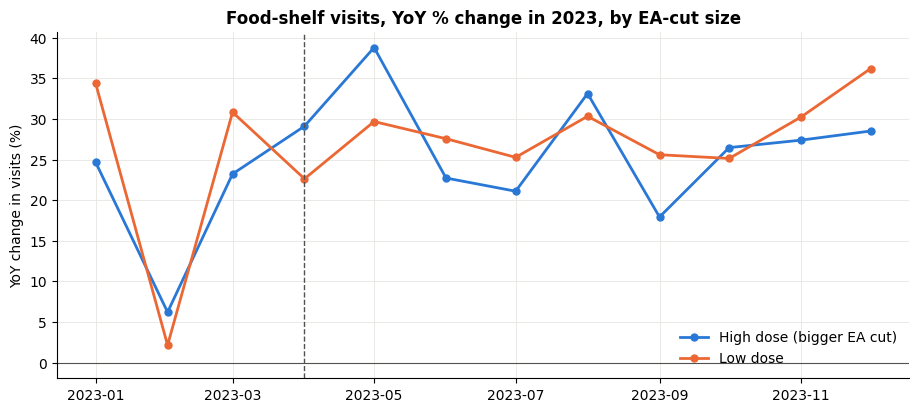

In [19]:
grp = (dose > dose.median()).map({True: "High dose (bigger EA cut)", False: "Low dose"})
es = panel.assign(group=panel["snap_unit"].map(grp)).dropna(subset=["yoy_visits", "group"])
es = es[(es["month"] >= "2023-01-01") & (es["month"] <= "2023-12-01")]
es_m = es.groupby(["month", "group"]).apply(
    lambda g: np.average(g["yoy_visits"], weights=g["visits"]), include_groups=False).unstack()

fig, ax = plt.subplots()
for col, color in zip(es_m.columns, [C1, C2]):
    ax.plot(es_m.index, es_m[col] * 100, marker="o", ms=5, color=color, label=col)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title("Food-shelf visits, YoY % change in 2023, by EA-cut size")
ax.set_ylabel("YoY change in visits (%)"); ax.legend(frameon=False)
plt.show()

> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- Both groups show **+20–40% YoY visit growth all through 2023, including Jan–Mar, before the cut**. Visits were already rising fast before EA ended (post-pandemic demand, food inflation).
- The two lines **do not separate after April**, consistent with the zero dose coefficient in §6.2.
- The **July 2023 spike (+297%) in the low-dose group** is the single-site data error from §2.1–2.5. It should disappear after re-running.

### 6.4 Second benefit change: the 2026 enrollment drop

> **Purpose:** Use the 2026 SNAP enrollment decline as a second, independent episode. Did counties that lost more SNAP enrollees see food-shelf visits rise more?

In [20]:
if panel["month"].max() >= pd.Timestamp("2026-03-01"):
    last = panel["month"].max()
    w26 = panel[(panel["month"] >= "2026-01-01") & (panel["month"] <= last)]
    d26 = w26.groupby("snap_unit")[["yoy_visits", "yoy_pounds", "yoy_snap_persons"]].mean().dropna()
    d26["metro"] = d26.index.isin(METRO7).astype(int)
    for y in ["yoy_visits", "yoy_pounds"]:
        m = smf.ols(f"{y} ~ yoy_snap_persons", data=d26).fit(cov_type="HC1")
        print(f"{y:12s} on YoY SNAP persons: coef={m.params['yoy_snap_persons']:.3f} "
              f"(se {m.bse['yoy_snap_persons']:.3f}, p={m.pvalues['yoy_snap_persons']:.3f}), n={len(d26)}")
else:
    print(f"Food-shelf data ends {panel['month'].max():%Y-%m}; 2026 analysis skipped.")

yoy_visits   on YoY SNAP persons: coef=-0.212 (se 0.284, p=0.455), n=82
yoy_pounds   on YoY SNAP persons: coef=-0.115 (se 0.474, p=0.808), n=82


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- Coefficient for visits = **−0.30 (p = 0.32)**. The negative sign means counties with bigger enrollment drops saw *higher* visit growth, the substitution direction, but the estimate is not statistically significant.
- Only Jan–Jul 2026 is available. Revisit when more 2026 food-shelf months arrive; it is the most policy-relevant episode for lawmakers.

## 7. Q5-C — Does the relationship differ across locations?

### 7.1 Metro vs Greater Minnesota

> **Purpose:** Test whether the SNAP–food-shelf relationship is different in the 7-county Twin Cities metro than in the rest of the state.

In [21]:
res_c = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    # metro main effect is absorbed by the unit fixed effects, so only the interactions are added
    m = fe_reg(panel, y, rhs="ln_snap_persons + ln_benefit_pp + ln_snap_persons:metro + ln_benefit_pp:metro")
    for v in ["ln_benefit_pp", "ln_benefit_pp:metro", "ln_snap_persons", "ln_snap_persons:metro"]:
        res_c.append({"outcome": y, "term": v, "coef": m.params.get(v, np.nan),
                      "se": m.bse.get(v, np.nan), "p": m.pvalues.get(v, np.nan)})
pd.DataFrame(res_c).round(3)

,outcome,term,coef,se,p
0,ln_visits,ln_benefit_pp,0.411,0.195,0.035
1,ln_visits,ln_benefit_pp:metro,0.057,0.145,0.694
2,ln_visits,ln_snap_persons,0.155,0.108,0.151
3,ln_visits,ln_snap_persons:metro,0.310,0.562,0.582
4,ln_pounds,ln_benefit_pp,0.238,0.205,0.244
5,ln_pounds,ln_benefit_pp:metro,-0.126,0.153,0.410
6,ln_pounds,ln_snap_persons,-0.074,0.125,0.553
7,ln_pounds,ln_snap_persons:metro,1.026,0.944,0.277
8,ln_individuals,ln_benefit_pp,0.214,0.197,0.276
9,ln_individuals,ln_benefit_pp:metro,-0.039,0.118,0.741


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- All `:metro` interaction terms are **not significant** (p = 0.17–0.72). The data show **no measurable metro vs Greater MN difference** in how food-shelf use tracks SNAP enrollment or benefit per person.
- Only 7 units are metro, so this test can only detect large differences.

### 7.2 County-by-county response to the EA cut

> **Purpose:** Show each unit's response so outliers and regional patterns are visible, and so the slide can name the counties that responded most.

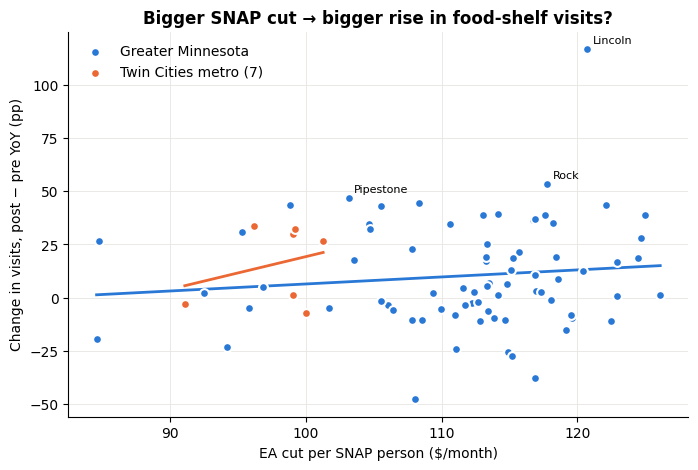

,dose,pre_yoy,post_yoy,did,metro
snap_unit,,,,,
Lincoln,120.750,-1.453,-0.286,1.168,0
Rock,117.770,-0.299,0.234,0.533,0
Pipestone,103.137,0.127,0.594,0.466,0
Wright,108.359,-0.074,0.369,0.443,0
Nobles,98.814,-0.195,0.241,0.435,0
Roseau,122.120,0.111,0.546,0.435,0
Kandiyohi,105.493,-0.192,0.238,0.429,0
McLeod,114.155,-0.933,-0.539,0.394,0
Brown,117.617,-0.179,0.211,0.390,0


In [22]:
d = ea_data["visits"]
fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(0, C1, "Greater Minnesota"), (1, C2, "Twin Cities metro (7)")]:
    s = d[d["metro"] == flag]
    ax.scatter(s["dose"], s["did"] * 100, s=40, color=color, label=label,
               edgecolor="white", linewidth=1.5, zorder=3)
    if len(s) > 2:
        b = np.polyfit(s["dose"], s["did"] * 100, 1)
        xs = np.linspace(s["dose"].min(), s["dose"].max(), 50)
        ax.plot(xs, np.polyval(b, xs), color=color, lw=2)
for unit, r in d.nlargest(3, "did").iterrows():
    ax.annotate(unit, (r["dose"], r["did"] * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("EA cut per SNAP person ($/month)")
ax.set_ylabel("Change in visits, post − pre YoY (pp)")
ax.set_title("Bigger SNAP cut → bigger rise in food-shelf visits?")
ax.legend(frameon=False)
plt.show()

d.sort_values("did", ascending=False)[["dose", "pre_yoy", "post_yoy", "did", "metro"]].round(3).head(10)

> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- Both fitted lines are **flat**: the size of a county's EA cut does not predict its change in visits, in either the metro or Greater MN.
- The labelled outliers (**MNPrairie +236 pp, Lincoln +117 pp, Polk +68 pp**) are far beyond any other unit and are likely driven by the single-site spikes fixed in §2.5. Check whether they remain after re-running before naming them on a slide.

## 8. Robustness checks

### 8.1 Balanced panel vs all sites

> **Purpose:** Check that the Q5-A conclusion does not depend on which sites are included.

In [23]:
checks = {"balanced panel (default)": panel, "all sites": panel_all}
rows = []
for name, p in checks.items():
    for y in ["ln_visits", "ln_pounds"]:
        m = fe_reg(p, y)
        rows.append({"version": name, "outcome": y,
                     "beta_persons": m.params["ln_snap_persons"], "beta_benefit_pp": m.params["ln_benefit_pp"],
                     "p_benefit_pp": m.pvalues["ln_benefit_pp"], "n": int(m.nobs)})
pd.DataFrame(rows).round(3)
# Also try: ERROR_POLICY="null_both", TRIBE_POLICY="drop", MIN_REPORT_SHARE=0.8 (edit Analysis Settings and re-run all)

,version,outcome,beta_persons,beta_benefit_pp,p_benefit_pp,n
0,balanced panel (default),ln_visits,0.160,0.400,0.038,4559
1,balanced panel (default),ln_pounds,-0.041,0.308,0.136,4558
2,all sites,ln_visits,0.239,-0.004,0.987,4561
3,all sites,ln_pounds,0.004,-0.010,0.965,4560


> **What this result means**  
_⟳ Numbers below are from the run **before** the v0.2 cleaning fixes (§2.2, §2.5). Re-run and update._
- The benefit-per-person coefficient for visits **flips from +0.39 (p = 0.04, balanced) to −0.03 (p = 0.90, all sites)**. The within-county result is **not robust**, which supports treating §5.3 as secondary.
- Enrollment stays small and positive in both versions (+0.17 / +0.26), so "enrollment and food-shelf use move together" is the more stable within-county finding.
- After re-running v0.2, also try `ERROR_POLICY="null_both"`, `TRIBE_POLICY="drop"`, and `MIN_REPORT_SHARE=0.8`.

## 9. Findings (draft from the v0.1 run — update after re-running v0.2)
| Sub-question | Answer | Evidence |
|---|---|---|
| **Q5-A. Together or substitute?** | **Both, at different levels.** SNAP *enrollment* moves **with** food-shelf use (both track need). SNAP *benefit per person* moves **against** it statewide: when benefits per person fell, visits and pounds rose within 0–3 months. The within-county regression adds no robust extra signal. | §5.1 chart, §5.2 lag correlations (≈ −0.5), §5.3 + §8 |
| **Q5-B. When benefits change?** | When EA ended (April 2023, −$100 per person, −38%), statewide visit growth rose about **15 percentage points** above its pre-cut pace. Because the cut was nearly uniform across counties, the county comparison cannot attribute the rise to EA alone; visits were already growing and food prices were high (Q4). | §6.1, §6.2, §6.3 |
| **Q5-C. Differs by location?** | **No measurable difference** between the Twin Cities metro and Greater Minnesota. No county-level dose-response pattern. | §7.1, §7.2 |

**Message for lawmakers (draft):** SNAP and food shelves are not interchangeable. When SNAP benefits per person dropped sharply in 2023, food-shelf visits kept climbing statewide, and food shelves handed out less food per visit (pounds grew slower than visits). Cutting SNAP shifts need onto a charitable system that is already stretched.

**Caveats to state on the slide:** accounting-month timing; one major policy event (EA end) overlaps with 2023 food inflation; SNAP and food-shelf geographies differ (consortia, Tribal Nations); pounds partly reflect supply, not just demand; individuals are self-reported; a share of site-months may be carried forward from the previous month (§2.5).